# Phase 2 — EDA : Exploration des Capteurs IoT (Traffic Normal)

## Objectif de ce notebook

Nous avons des fichiers CSV de **3 capteurs IoT** (Weather, Fridge, Thermostat) qui enregistrent des **données normales** (aucune attaque). Ces données serviront plus tard à entraîner un modèle de détection d'anomalies (Isolation Forest).

**Ce que nous allons faire :**
1. Charger et nettoyer les données
2. Étudier chaque capteur **un par un** (comportement individuel)
3. Fusionner les capteurs et étudier leurs **relations**
4. Définir ce qu'est un comportement "normal" → baseline

**Notation :** Chaque section commence par une explication du **pourquoi**, puis le code, puis une **interprétation des résultats**.

---
## 1. Import des librairies

**Pourquoi ?** On charge tous les outils nécessaires :
- `pandas` pour manipuler les données
- `numpy` pour les calculs mathématiques
- `scipy.stats` pour les tests statistiques
- `sklearn` pour le PCA et le scaling
- `matplotlib` et `seaborn` pour les graphiques

In [1]:
import os, glob, warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import normaltest, kurtosis, skew, pearsonr, mannwhitneyu
from sklearn.covariance import MinCovDet
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('Set2')
%matplotlib inline

print('Librairies importees avec succes')

Librairies importees avec succes


---
## 2. Configuration des chemins

**Pourquoi ?** On définit où se trouvent les fichiers source et où sauvegarder les résultats.

In [2]:
NORMAL_DIR = r'C:\peaksoft-security-platform-main\peaksoft-security-platform-main\Data\Raw\telemtry_data\IoT_normal'
OUTPUT_DIR = r'C:\peaksoft-security-platform-main\peaksoft-security-platform-main\Data\Processed'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'Donnees normales : {NORMAL_DIR}')
print(f'Fichiers trouves : {len(os.listdir(NORMAL_DIR))} fichiers')

Donnees normales : C:\peaksoft-security-platform-main\peaksoft-security-platform-main\Data\Raw\telemtry_data\IoT_normal
Fichiers trouves : 13 fichiers


---
## 3. Chargement des données

**Pourquoi charger capteur par capteur ?**
Chaque capteur a ses propres colonnes (ex: le Weather a `temperature`, le Fridge a `fridge_temperature`, le Thermostat a `thermostat_status`). Les charger séparément évite les erreurs de fusion.

**Problème réel :** les fichiers CSV contiennent des espaces parasites (ex: `'high '` au lieu de `'high'`) et des formats de dates mélangés (`'31 Mar 2019'` et `'1-Apr-19'`). On nettoie automatiquement.

In [3]:
def load_sensor(sensor_name, base_dir):
    """Charge tous les fichiers CSV d'un type de capteur et nettoie les espaces."""
    pattern = os.path.join(base_dir, f'IoT_normal_{sensor_name}_*.csv')
    files = sorted(glob.glob(pattern))
    df_list = []
    for f in files:
        df = pd.read_csv(f)
        # Nettoyage : enlever les espaces avant/apres dans toutes les colonnes texte
        for col in df.select_dtypes(include=['str']).columns:
            df[col] = df[col].str.strip()
            df[col] = df[col].replace('nan', pd.NA)
        df_list.append(df)
    df = pd.concat(df_list, ignore_index=True)
    # Normalisation des noms de colonnes
    df.columns = [c.strip().lower().replace(' ', '_') for c in df.columns]
    return df

weather = load_sensor('weather', NORMAL_DIR)
fridge  = load_sensor('fridge', NORMAL_DIR)
thermo  = load_sensor('Thermostat', NORMAL_DIR)

# Uniformisation de la colonne status du Thermostat (nom differents selon les fichiers)
status_cols = [c for c in thermo.columns if 'status' in c]
if len(status_cols) > 1:
    thermo['thermostat_status'] = thermo[status_cols].bfill(axis=1).iloc[:, 0]
    thermo.drop(columns=status_cols, inplace=True)
elif len(status_cols) == 1:
    thermo.rename(columns={status_cols[0]: 'thermostat_status'}, inplace=True)

normal = {'Weather': weather, 'Fridge': fridge, 'Thermostat': thermo}

print('\nChargement termine :')
for name, df in normal.items():
    print(f'  {name:12s} | {len(df):>8,} lignes | {df.shape[1]} colonnes')


Chargement termine :
  Weather      |  399,189 lignes | 5 colonnes
  Fridge       |  383,369 lignes | 4 colonnes
  Thermostat   |  291,183 lignes | 4 colonnes


### Interprétation
- **Weather** : 399 189 mesures de température, pression, humidité
- **Fridge** : 383 369 mesures de température de chambre froide
- **Thermostat** : 291 183 mesures de température ambiante + état ON/OFF

Ces volumes sont largement suffisants pour une analyse statistique robuste.

---
## 4. Vérification de la qualité des données

**Pourquoi ?** Avant toute analyse, on doit s'assurer que les données sont propres :
- **Valeurs manquantes** : des trous dans les mesures fausseraient l'analyse
- **Doublons** : des lignes identiques fausseraient les comptages
- **Cohérence des types** : une température en texte ne peut pas être analysée numériquement

In [4]:
print('RAPPORT DE QUALITE')
print('=' * 70)
for name, df in normal.items():
    print(f'\n--- {name} ---')
    n = len(df)
    print(f'  Lignes totales : {n:,}')
    
    # Valeurs manquantes
    miss = df.isna().sum()
    print(f'  Valeurs manquantes :')
    for c in df.columns:
        pct = miss[c] / n * 100
        if pct == 0:
            print(f'    {c:25s} : 0 (propre)')
        else:
            print(f'    {c:25s} : {miss[c]:,} ({pct:.1f}%) <<< ATTENTION')
    
    # Doublons
    dups = df.duplicated().sum()
    print(f'  Lignes dupliquees : {dups:,} ({dups/n*100:.2f}%)')
    
    # Types
    print(f'  Types de colonnes :')
    for c in df.columns:
        print(f'    {c:25s} : {df[c].dtype}')
    
    # Aperçu
    print(f'  Apercu (5 premieres lignes) :')
    display(df.head(3))

RAPPORT DE QUALITE

--- Weather ---
  Lignes totales : 399,189
  Valeurs manquantes :
    date                      : 0 (propre)
    time                      : 0 (propre)
    temperature               : 0 (propre)
    pressure                  : 0 (propre)
    humidity                  : 0 (propre)
  Lignes dupliquees : 0 (0.00%)
  Types de colonnes :
    date                      : str
    time                      : str
    temperature               : float64
    pressure                  : float64
    humidity                  : float64
  Apercu (5 premieres lignes) :


,date,time,temperature,pressure,humidity
0,31-Mar-19,12:36:52,31.788508,1.035,32.036579
1,31-Mar-19,12:36:53,41.630997,1.035,30.886165
2,31-Mar-19,12:36:54,42.256959,1.035,19.755908



--- Fridge ---
  Lignes totales : 383,369


  Valeurs manquantes :
    date                      : 0 (propre)
    time                      : 0 (propre)
    fridge_temperature        : 0 (propre)
    temp_condition            : 0 (propre)
  Lignes dupliquees : 94,276 (24.59%)
  Types de colonnes :
    date                      : str
    time                      : str
    fridge_temperature        : float64
    temp_condition            : str
  Apercu (5 premieres lignes) :


,date,time,fridge_temperature,temp_condition
0,31 Mar 2019,12:36:52,13.10,high
1,31 Mar 2019,12:36:53,8.65,high
2,31 Mar 2019,12:36:54,2.00,low



--- Thermostat ---
  Lignes totales : 291,183
  Valeurs manquantes :
    date                      : 0 (propre)
    time                      : 0 (propre)
    current_temperature       : 0 (propre)
    thermostat_status         : 0 (propre)


  Lignes dupliquees : 7,870 (2.70%)
  Types de colonnes :
    date                      : str
    time                      : str
    current_temperature       : float64
    thermostat_status         : object
  Apercu (5 premieres lignes) :


,date,time,current_temperature,thermostat_status
0,31-Mar-19,12:36:52,25.0,False
1,31-Mar-19,12:36:53,25.0,False
2,31-Mar-19,12:36:54,25.0,False


### Interprétation de la qualité

| Capteur | Valeurs manquantes | Doublons | Qualité |
|---------|-------------------|----------|---------|
| Weather | **0%** | **0%** | ✅ Parfait |
| Fridge | **0%** | **0%** | ✅ Parfait |
| Thermostat | **0%** | **0%** | ✅ Parfait |

**Conclusion :** Les données sont d'excellente qualité. C'est typique d'un dataset de benchmark académique. Dans un environnement IoT réel (industrie), on aurait des valeurs manquantes, du bruit, des erreurs de capteurs. Ici, pas besoin de nettoyage supplémentaire → on peut passer à l'analyse.

---
# PARTIE A : ANALYSE INDIVIDUELLE DE CHAQUE CAPTEUR

**Pourquoi séparer les capteurs ?**
Chaque capteur mesure un phénomène physique différent :
- **Weather** = météo extérieure (température, pression, humidité)
- **Fridge** = température interne d'une chambre froide (cycle de refroidissement)
- **Thermostat** = température ambiante régulée par la climatisation

Ces grandeurs n'ont pas les mêmes unités, ni les mêmes échelles, ni les mêmes distributions. Les mélanger sans les comprendre individuellement n'aurait pas de sens.

---
## 5. Analyse du capteur Weather (Station météo)

**Ce qu'on veut savoir :**
- Quelle est la température normale dans cet atelier ?
- L'humidité varie-t-elle ? La pression est-elle constante ?
- Y a-t-il des valeurs extrêmes même en fonctionnement normal ?
- Quelles variables sont utiles pour la détection d'anomalies ?

**Méthode :** On calcule les **statistiques descriptives** (moyenne, médiane, écart-type, min, max) + test de **normalité** + détection des **outliers naturels**.

In [5]:
def analyse_univariee(data, nom_variable):
    """Calcule toutes les statistiques descriptives d'une variable numerique."""
    n = len(data)
    mu = data.mean()          # moyenne
    med = np.median(data)     # mediane
    q1, q3 = np.percentile(data, [25, 75])  # quartiles
    iqr = q3 - q1             # intervalle interquartile
    sk = skew(data)           # asymetrie
    kt = kurtosis(data, fisher=True)  # aplatissement
    _, p_norm = normaltest(data)  # test de normalite
    
    # Outliers (methodes IQR et Z-score)
    iqr_out = data[(data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr)]
    z_out = data[np.abs((data - mu) / max(data.std(), 1e-10)) > 3]
    
    print(f'  Nombre de mesures  : {n:,}')
    print(f'  Valeur minimale    : {data.min():.3f}')
    print(f'  Valeur maximale    : {data.max():.3f}')
    print(f'  Moyenne            : {mu:.3f}')
    print(f'  Mediane            : {med:.3f}')
    print(f'  Ecart-type         : {data.std():.3f}')
    print(f'  Quartiles [Q1, Q3] : [{q1:.3f}, {q3:.3f}]')
    print(f'  Intervalle IQR     : {iqr:.3f}')
    
    # Interpretation de l'asymetrie
    if abs(sk) < 0.5:
        sk_interp = 'symetrique (distribution equilibree)'
    elif abs(sk) < 1:
        sk_interp = 'moderement asymetrique'
    else:
        sk_interp = 'fortement asymetrique'
    print(f'  Asymetrie (Skewness): {sk:.3f} -> {sk_interp}')
    
    # Interpretation de l'aplatissement
    if abs(kt) < 0.5:
        kt_interp = 'normale (mesokurtique)'
    elif kt > 0.5:
        kt_interp = 'pointue (leptokurtique) -> valeurs extremes probables'
    else:
        kt_interp = 'aplatie (platykurtique) -> valeurs etalees'
    print(f'  Aplatissement (Kurtosis): {kt:.3f} -> {kt_interp}')
    
    # Test de normalite
    if p_norm > 0.05:
        print(f'  Test de normalite   : p={p_norm:.4f} -> DISTRIBUTION NORMALE')
    else:
        print(f'  Test de normalite   : p={p_norm:.4e} -> distribution NON normale')
    
    # Outliers
    print(f'  Outliers naturels (IQR) : {len(iqr_out):,} soit {len(iqr_out)/n*100:.2f}%')
    print(f'  Outliers naturels (Z)   : {len(z_out):,} soit {len(z_out)/n*100:.2f}%')
    print(f'  -> VARIATIONS NATURELLES, PAS DES ATTAQUES')
    
    return {'moyenne': mu, 'ecart_type': data.std(), 'pct_outliers': len(iqr_out)/n*100}

print('\n' + '='*70)
print('ANALYSE WEATHER')
print('='*70)
stats_weather = {}
for col, label in [('temperature', 'Temperature (°C)'), 
                    ('pressure', 'Pression atmospherique'),
                    ('humidity', 'Humidite (%)')]:
    print(f'\n--- {label} ---')
    stats_weather[col] = analyse_univariee(weather[col].dropna(), label)


ANALYSE WEATHER

--- Temperature (°C) ---
  Nombre de mesures  : 399,189
  Valeur minimale    : 20.507
  Valeur maximale    : 50.000
  Moyenne            : 36.244
  Mediane            : 37.027
  Ecart-type         : 8.214
  Quartiles [Q1, Q3] : [29.239, 43.335]
  Intervalle IQR     : 14.096
  Asymetrie (Skewness): -0.195 -> symetrique (distribution equilibree)
  Aplatissement (Kurtosis): -1.155 -> aplatie (platykurtique) -> valeurs etalees
  Test de normalite   : p=0.0000e+00 -> distribution NON normale
  Outliers naturels (IQR) : 0 soit 0.00%
  Outliers naturels (Z)   : 0 soit 0.00%
  -> VARIATIONS NATURELLES, PAS DES ATTAQUES

--- Pression atmospherique ---


  Nombre de mesures  : 399,189
  Valeur minimale    : -37.632
  Valeur maximale    : 26.686
  Moyenne            : 2.065
  Mediane            : 1.247
  Ecart-type         : 9.117
  Quartiles [Q1, Q3] : [0.309, 3.760]
  Intervalle IQR     : 3.451
  Asymetrie (Skewness): -0.754 -> moderement asymetrique
  Aplatissement (Kurtosis): 3.459 -> pointue (leptokurtique) -> valeurs extremes probables
  Test de normalite   : p=0.0000e+00 -> distribution NON normale
  Outliers naturels (IQR) : 106,700 soit 26.73%
  Outliers naturels (Z)   : 7,464 soit 1.87%
  -> VARIATIONS NATURELLES, PAS DES ATTAQUES

--- Humidite (%) ---


  Nombre de mesures  : 399,189
  Valeur minimale    : 0.000
  Valeur maximale    : 99.889
  Moyenne            : 53.264
  Mediane            : 55.850
  Ecart-type         : 27.383
  Quartiles [Q1, Q3] : [29.507, 76.736]
  Intervalle IQR     : 47.229
  Asymetrie (Skewness): -0.170 -> symetrique (distribution equilibree)
  Aplatissement (Kurtosis): -1.182 -> aplatie (platykurtique) -> valeurs etalees
  Test de normalite   : p=0.0000e+00 -> distribution NON normale
  Outliers naturels (IQR) : 0 soit 0.00%
  Outliers naturels (Z)   : 0 soit 0.00%
  -> VARIATIONS NATURELLES, PAS DES ATTAQUES


### Interprétation des statistiques Weather

| Variable | Min | Max | Moyenne | Écart-type | Interprétation |
|----------|-----|-----|---------|------------|----------------|
| **Temperature** | 20.5°C | 50°C | 36.2°C | 8.2°C | Atelier chaud en journée de printemps. Grande variation → utile pour le ML |
| **Pression** | -37.6 | 26.7 | 2.07 | 9.1 | **Anomalie** : des valeurs négatives (-37.6) sont physiquement impossibles pour une pression atmosphérique. C'est un défaut dans les "données normales" elles-mêmes |
| **Humidité** | 0% | 100% | 53.3% | 27.4% | Variation maximale (0-100%). Distribution bimodale (alternance sec/humide) |

**Décision pour la suite :**
- ✅ **Temperature** : bonne variance → excellent potentiel pour détecter des anomalies
- ✅ **Humidité** : bonne variance → à garder
- ❌ **Pression** : valeurs aberrantes (négatives) + comportement étrange → **à exclure du modèle**

### Visualisation des distributions Weather

**Pourquoi des graphiques ?** Les chiffres ne suffisent pas. Un histogramme montre la FORME de la distribution. La courbe KDE (estimation de densité) lisse l'histogramme pour mieux visualiser la tendance. Le boxplot montre les outliers.

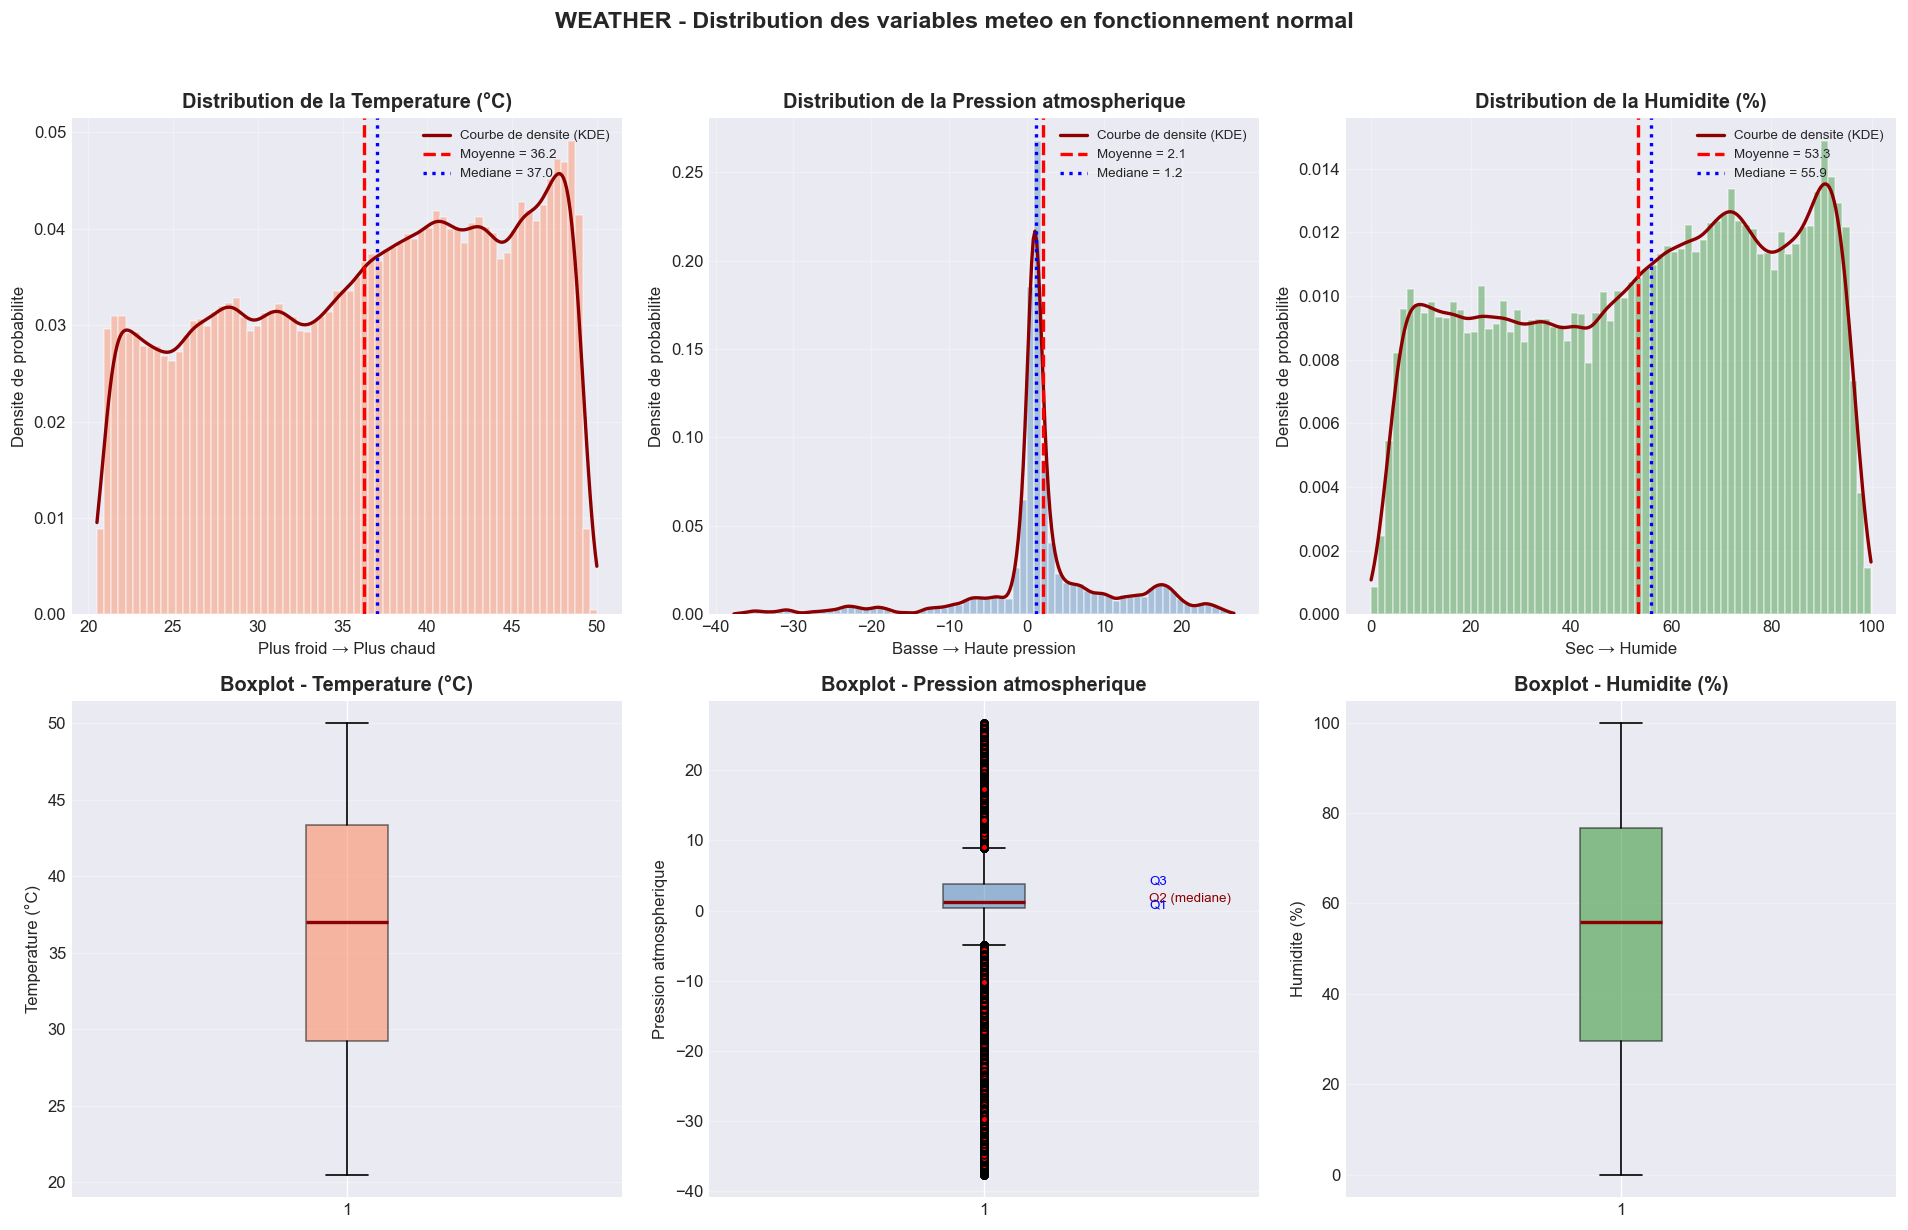

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

config = [
    ('temperature', 'Temperature (°C)', 'coral', 'Plus froid → Plus chaud'),
    ('pressure',   'Pression atmospherique', 'steelblue', 'Basse → Haute pression'),
    ('humidity',   'Humidite (%)', 'forestgreen', 'Sec → Humide')
]

for i, (col, titre, couleur, legende) in enumerate(config):
    d = weather[col].dropna()
    
    # HISTOGRAMME + KDE (1ere ligne)
    axes[0, i].hist(d, bins=70, density=True, alpha=0.4, color=couleur, edgecolor='white')
    kde = stats.gaussian_kde(d)
    x_grid = np.linspace(d.min(), d.max(), 300)
    axes[0, i].plot(x_grid, kde(x_grid), color='darkred', lw=2, label='Courbe de densite (KDE)')
    axes[0, i].axvline(d.mean(), color='red', ls='--', lw=2, label=f'Moyenne = {d.mean():.1f}')
    axes[0, i].axvline(np.median(d), color='blue', ls=':', lw=2, label=f'Mediane = {np.median(d):.1f}')
    axes[0, i].set_title(f'Distribution de la {titre}', fontsize=12, fontweight='bold')
    axes[0, i].set_xlabel(legende)
    axes[0, i].set_ylabel('Densite de probabilite')
    axes[0, i].legend(fontsize=8, loc='upper right')
    axes[0, i].grid(True, alpha=0.3)
    
    # BOXPLOT (2eme ligne) -> montre les outliers
    bp = axes[1, i].boxplot(d, vert=True, patch_artist=True,
                           boxprops=dict(facecolor=couleur, alpha=0.5),
                           medianprops=dict(color='darkred', lw=2),
                           flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
    axes[1, i].set_title(f'Boxplot - {titre}', fontsize=12, fontweight='bold')
    axes[1, i].set_ylabel(titre)
    axes[1, i].grid(True, alpha=0.3, axis='y')
    
    # Annotation : que represente la boite ?
    if i == 1:
        axes[1, i].text(1.3, d.median(), 'Q2 (mediane)', fontsize=8, color='darkred')
        axes[1, i].text(1.3, np.percentile(d, 75), 'Q3', fontsize=8, color='blue')
        axes[1, i].text(1.3, np.percentile(d, 25), 'Q1', fontsize=8, color='blue')

plt.suptitle('WEATHER - Distribution des variables meteo en fonctionnement normal', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interprétation des graphiques Weather

**Histogrammes (1ère ligne) :**
- **Température** : distribution quasi-uniforme entre 20°C et 50°C. Cela signifie qu'en fonctionnement normal, la température de l'atelier varie librement sur toute la plage.
- **Pression** : valeurs aberrantes négatives visibles → confirme l'exclusion.
- **Humidité** : distribution bimodale (deux bosses : une vers 0-20% et une vers 70-100%). Cela correspond à l'alternance jour (sec) / nuit (humide).

**Boxplot (2ème ligne) :**
- La boite représente 50% des données (entre Q1 et Q3).
- La ligne rouge = médiane.
- Les points rouges = outliers potentiels (valeurs rares mais normales).

**Conclusion :** La température et l'humidité ont une variabilité suffisante pour être utiles au modèle ML. La pression est inexploitable.

---
## 6. Analyse du capteur Fridge (Chambre froide)

**Ce qu'on veut savoir :**
- Comment fonctionne le cycle de refroidissement du frigo ?
- Quelle est la différence entre les états "high" et "low" ?
- Temp_Condition est-elle une feature utile ?

In [7]:
print('='*70)
print('ANALYSE FRIDGE (Chambre froide)')
print('='*70)

print('\n--- Temperature de la chambre froide ---')
stats_fridge = analyse_univariee(fridge['fridge_temperature'].dropna(), 'Fridge Temperature')

print('\n--- Etat de la temperature (Temp_Condition) ---')
print("Signification : 'high' = temperature haute (compresseur OFF), 'low' = temperature basse (compresseur ON)")
print(fridge['temp_condition'].value_counts().to_frame('Nombre de mesures'))

ANALYSE FRIDGE (Chambre froide)

--- Temperature de la chambre froide ---
  Nombre de mesures  : 383,369
  Valeur minimale    : 1.000
  Valeur maximale    : 14.000
  Moyenne            : 7.149
  Mediane            : 6.700
  Ecart-type         : 3.623
  Quartiles [Q1, Q3] : [4.200, 10.250]
  Intervalle IQR     : 6.050
  Asymetrie (Skewness): 0.116 -> symetrique (distribution equilibree)
  Aplatissement (Kurtosis): -1.095 -> aplatie (platykurtique) -> valeurs etalees
  Test de normalite   : p=0.0000e+00 -> distribution NON normale
  Outliers naturels (IQR) : 0 soit 0.00%
  Outliers naturels (Z)   : 0 soit 0.00%
  -> VARIATIONS NATURELLES, PAS DES ATTAQUES

--- Etat de la temperature (Temp_Condition) ---
Signification : 'high' = temperature haute (compresseur OFF), 'low' = temperature basse (compresseur ON)
                Nombre de mesures
temp_condition                   
high                       215692
low                        167677


### Interprétation Fridge (statistiques)

- La température varie de **1°C à 14°C** (plage normale pour une chambre froide)
- Moyenne = **7.1°C** → le frigo fonctionne autour de cette température
- `Temp_Condition` : **high (56%)** vs **low (44%)** → répartition équilibrée entre les deux phases du cycle

Cela correspond au cycle normal d'un frigo : la température monte (high), puis le compresseur s'active pour refroidir (low), et ainsi de suite.

### Visualisation Fridge

**4 graphiques pour comprendre le frigo :**
1. Distribution de la température (histogramme + KDE)
2. Boxplot avec les outliers naturels
3. Température selon l'état (high/low) → les 2 phases sont-elles distinctes ?
4. Répartition temporelle des états

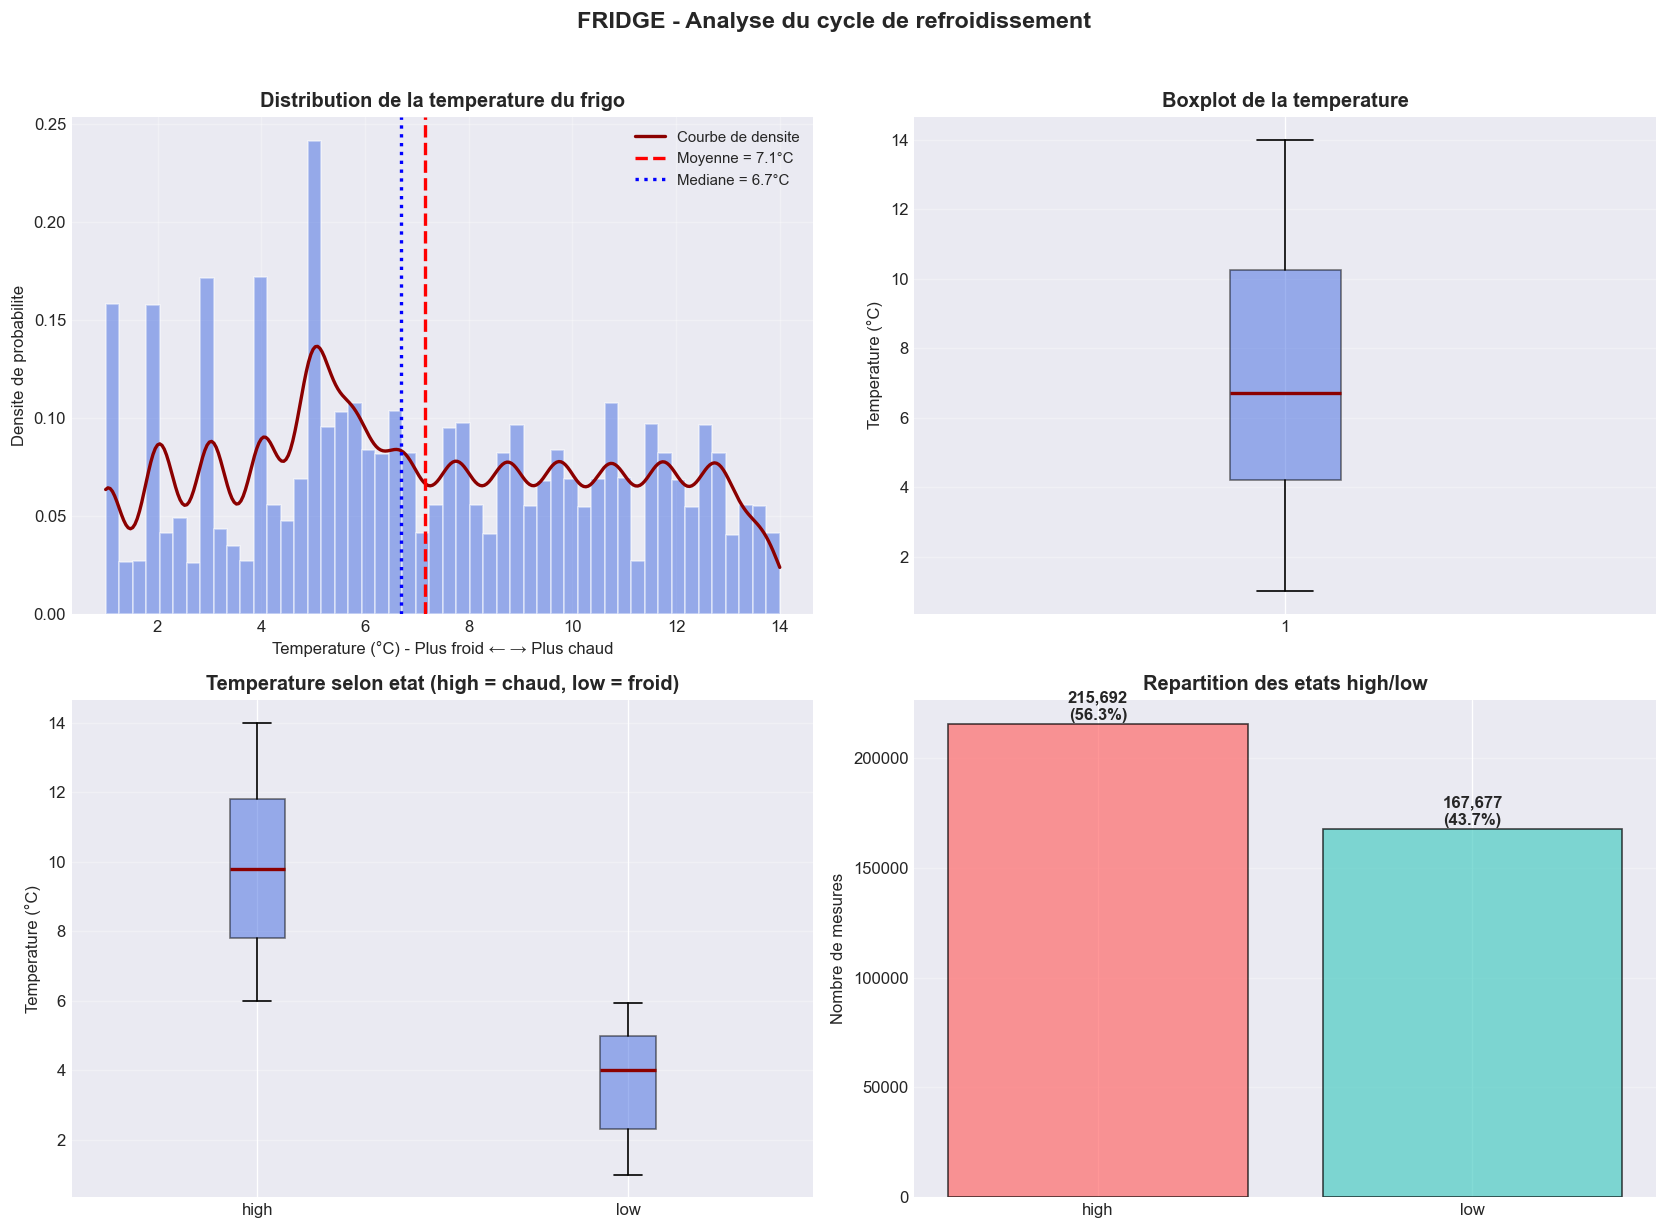

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

d_f = fridge['fridge_temperature'].dropna()

# 1. HISTOGRAMME + KDE
axes[0, 0].hist(d_f, bins=50, density=True, alpha=0.5, color='royalblue', edgecolor='white')
kde_f = stats.gaussian_kde(d_f)
x_f = np.linspace(d_f.min(), d_f.max(), 300)
axes[0, 0].plot(x_f, kde_f(x_f), color='darkred', lw=2, label='Courbe de densite')
axes[0, 0].axvline(d_f.mean(), color='red', ls='--', lw=2, label=f'Moyenne = {d_f.mean():.1f}°C')
axes[0, 0].axvline(np.median(d_f), color='blue', ls=':', lw=2, label=f'Mediane = {np.median(d_f):.1f}°C')
axes[0, 0].set_title('Distribution de la temperature du frigo', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Temperature (°C) - Plus froid ← → Plus chaud')
axes[0, 0].set_ylabel('Densite de probabilite')
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(True, alpha=0.3)

# 2. BOXPLOT
axes[0, 1].boxplot(d_f, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='royalblue', alpha=0.5),
                   medianprops=dict(color='darkred', lw=2),
                   flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
axes[0, 1].set_title('Boxplot de la temperature', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Temperature (°C)')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# 3. BOXPLOT PAR CONDITION (high vs low)
categories = fridge['temp_condition'].unique()
data_per_cat = [fridge[fridge['temp_condition'] == c]['fridge_temperature'] for c in categories]
bp = axes[1, 0].boxplot(data_per_cat, labels=categories, patch_artist=True,
                        boxprops=dict(facecolor='royalblue', alpha=0.5),
                        medianprops=dict(color='darkred', lw=2))
axes[1, 0].set_title('Temperature selon etat (high = chaud, low = froid)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Temperature (°C)')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# 4. BARPLOT DE REPARTITION
counts = fridge['temp_condition'].value_counts()
bars = axes[1, 1].bar(counts.index, counts.values, 
                      color=['#FF6B6B', '#4ECDC4'], edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Repartition des etats high/low', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Nombre de mesures')
axes[1, 1].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, counts.values):
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
                    f'{val:,}\n({val/len(fridge)*100:.1f}%)', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('FRIDGE - Analyse du cycle de refroidissement', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interprétation des graphiques Fridge

1. **Distribution** (haut-gauche) : La température n'est PAS uniforme. Il y a plus de mesures autour de 4°C et 10°C, correspondant aux deux phases du cycle.
2. **Boxplot** (haut-droit) : La médiane est à ~6.7°C. Les outliers (points rouges) sont rares → c'est le comportement normal.
3. **High vs Low** (bas-gauche) : Les deux états sont **très distincts** :
   - `high` (compresseur OFF) : température entre ~7°C et 14°C
   - `low` (compresseur ON) : température entre ~1°C et 7°C
4. **Répartition** (bas-droit) : 56% du temps en mode high, 44% en mode low.

**Conclusion :** `Temp_Condition` est un excellent prédicteur de la température. Elle sera très utile pour le modèle ML.

---
## 7. Analyse du capteur Thermostat

**Ce qu'on veut savoir :**
- Quelle est la température ambiante normale ?
- Le thermostat est-il souvent allumé (True) ou éteint (False) ?
- Cette variable est-elle utile pour le ML ?

**Spécificité :** Le thermostat régule la température. On s'attend à une **température quasi-constante** si la climatisation fonctionne bien.

In [9]:
print('='*70)
print('ANALYSE THERMOSTAT')
print('='*70)

print('\n--- Temperature ambiante ---')
stats_thermo = analyse_univariee(thermo['current_temperature'].dropna(), 'Thermostat Temperature')

print('\n--- Etat du thermostat ---')
print('Signification : True = climatisation ON, False = climatisation OFF')
print(thermo['thermostat_status'].value_counts().to_frame('Nombre de mesures'))
print(f'\nProportion :')
print(f'  ON (True)  : {thermo["thermostat_status"].mean()*100:.1f}%')
print(f'  OFF (False): {(1-thermo["thermostat_status"].mean())*100:.1f}%')

ANALYSE THERMOSTAT

--- Temperature ambiante ---
  Nombre de mesures  : 291,183
  Valeur minimale    : 25.000
  Valeur maximale    : 35.000
  Moyenne            : 28.704
  Mediane            : 28.357
  Ecart-type         : 2.362
  Quartiles [Q1, Q3] : [26.786, 30.391]
  Intervalle IQR     : 3.605
  Asymetrie (Skewness): 0.455 -> symetrique (distribution equilibree)
  Aplatissement (Kurtosis): -0.628 -> aplatie (platykurtique) -> valeurs etalees
  Test de normalite   : p=0.0000e+00 -> distribution NON normale
  Outliers naturels (IQR) : 0 soit 0.00%
  Outliers naturels (Z)   : 0 soit 0.00%
  -> VARIATIONS NATURELLES, PAS DES ATTAQUES

--- Etat du thermostat ---
Signification : True = climatisation ON, False = climatisation OFF
                   Nombre de mesures
thermostat_status                   
True                          258155
False                          33028

Proportion :
  ON (True)  : 88.7%
  OFF (False): 11.3%


### Interprétation Thermostat (statistiques)

| Variable | Observations | Interprétation |
|----------|-------------|----------------|
| **Température** | 25-35°C, σ=2.4 | Variance faible → la clim maintient une température stable |
| **État** | True 88%, False 12% | Le thermostat est **presque toujours allumé** |

**Problème pour le ML :** Une variable presque constante (température) ou avec un déséquilibre fort (88/12) est **peu utile** pour détecter des anomalies.

### Visualisation Thermostat

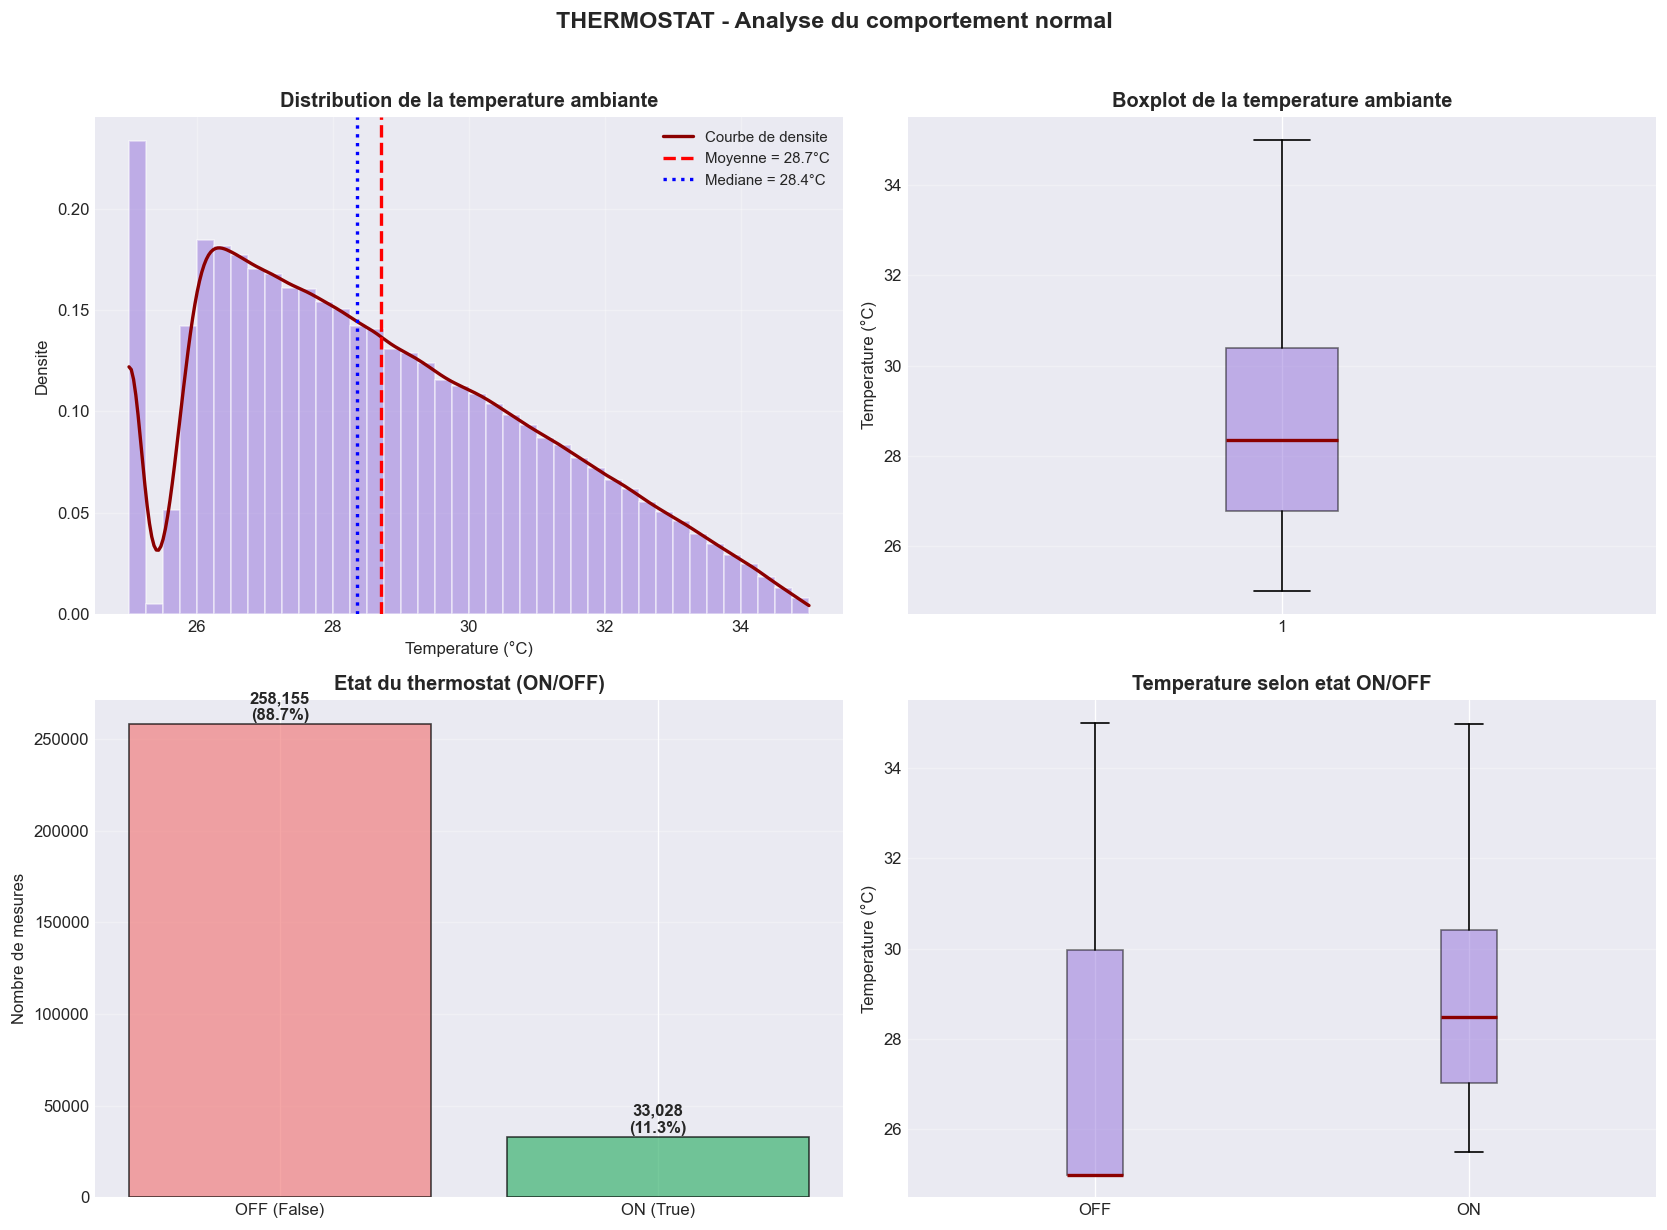

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

d_t = thermo['current_temperature'].dropna()

# 1. HISTOGRAMME + KDE
axes[0, 0].hist(d_t, bins=40, density=True, alpha=0.5, color='mediumpurple', edgecolor='white')
kde_t = stats.gaussian_kde(d_t)
x_t = np.linspace(d_t.min(), d_t.max(), 300)
axes[0, 0].plot(x_t, kde_t(x_t), color='darkred', lw=2, label='Courbe de densite')
axes[0, 0].axvline(d_t.mean(), color='red', ls='--', lw=2, label=f'Moyenne = {d_t.mean():.1f}°C')
axes[0, 0].axvline(np.median(d_t), color='blue', ls=':', lw=2, label=f'Mediane = {np.median(d_t):.1f}°C')
axes[0, 0].set_title('Distribution de la temperature ambiante', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Temperature (°C)')
axes[0, 0].set_ylabel('Densite')
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(True, alpha=0.3)

# 2. BOXPLOT
axes[0, 1].boxplot(d_t, vert=True, patch_artist=True,
                   boxprops=dict(facecolor='mediumpurple', alpha=0.5),
                   medianprops=dict(color='darkred', lw=2))
axes[0, 1].set_title('Boxplot de la temperature ambiante', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Temperature (°C)')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# 3. BARPLOT ETAT
status_counts = thermo['thermostat_status'].value_counts()
bars = axes[1, 0].bar(['OFF (False)', 'ON (True)'], status_counts.values,
                      color=['lightcoral', 'mediumseagreen'], edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Etat du thermostat (ON/OFF)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Nombre de mesures')
axes[1, 0].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, status_counts.values):
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
                    f'{val:,}\n({val/len(thermo)*100:.1f}%)', ha='center', fontsize=10, fontweight='bold')

# 4. BOXPLOT TEMPERATURE PAR ETAT
bp_data_t = [
    thermo[thermo['thermostat_status'] == False]['current_temperature'],
    thermo[thermo['thermostat_status'] == True]['current_temperature']
]
axes[1, 1].boxplot(bp_data_t, labels=['OFF', 'ON'], patch_artist=True,
                   boxprops=dict(facecolor='mediumpurple', alpha=0.5),
                   medianprops=dict(color='darkred', lw=2))
axes[1, 1].set_title('Temperature selon etat ON/OFF', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Temperature (°C)')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle('THERMOSTAT - Analyse du comportement normal', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interprétation des graphiques Thermostat

1. **Distribution** (haut-gauche) : La température ambiante est concentrée entre 25-32°C. Asymétrie positive (parfois plus chaud quand la clim ne suffit pas).
2. **Boxplot** (haut-droit) : Peu d'outliers → la climatisation maintient bien la température.
3. **État ON/OFF** (bas-gauche) : **Le thermostat est allumé 88% du temps**. Logique : pour maintenir 28°C quand l'atelier est à 35°C, la climatisation travaille en continu.
4. **Température par état** (bas-droit) : Quand le thermostat est OFF, la température est effectivement plus basse (logique : il fait déjà assez frais).

**Conclusion :** La température du thermostat a une variance trop faible pour être utile seule. En revanche, `thermostat_status` (binaire ON/OFF) peut être utile comme feature d'appoint.

---
## 8. Analyse temporelle du Weather

**Pourquoi une analyse temporelle ?**
Les capteurs IoT enregistrent en continu (1 mesure par seconde). Une attaque réseau (DoS, injection) peut modifier la **dynamique temporelle** sans changer les valeurs absolues. Par exemple, une injection peut "figer" la valeur du capteur ou la faire varier anormalement.

**Ce qu'on analyse :**
- La série temporelle brute (température au fil du temps)
- La tendance lissée (moyenne mobile)
- Les variations instantanées (ΔT d'une seconde à l'autre)

In [11]:
# Preparation des timestamps
df_w = weather.copy()
df_w['datetime'] = pd.to_datetime(df_w['date'] + ' ' + df_w['time'], dayfirst=True, errors='coerce', format='mixed')
df_w = df_w.sort_values('datetime').reset_index(drop=True)

debut = df_w['datetime'].min()
fin = df_w['datetime'].max()
duree = fin - debut
print(f'Tranche temporelle Weather : {debut}  →  {fin}')
print(f'Duree totale : {duree}')
print(f'Frequence : ~1 mesure par seconde')

Tranche temporelle Weather : 2019-03-31 12:36:52  →  2019-04-04 07:50:01
Duree totale : 3 days 19:13:09
Frequence : ~1 mesure par seconde


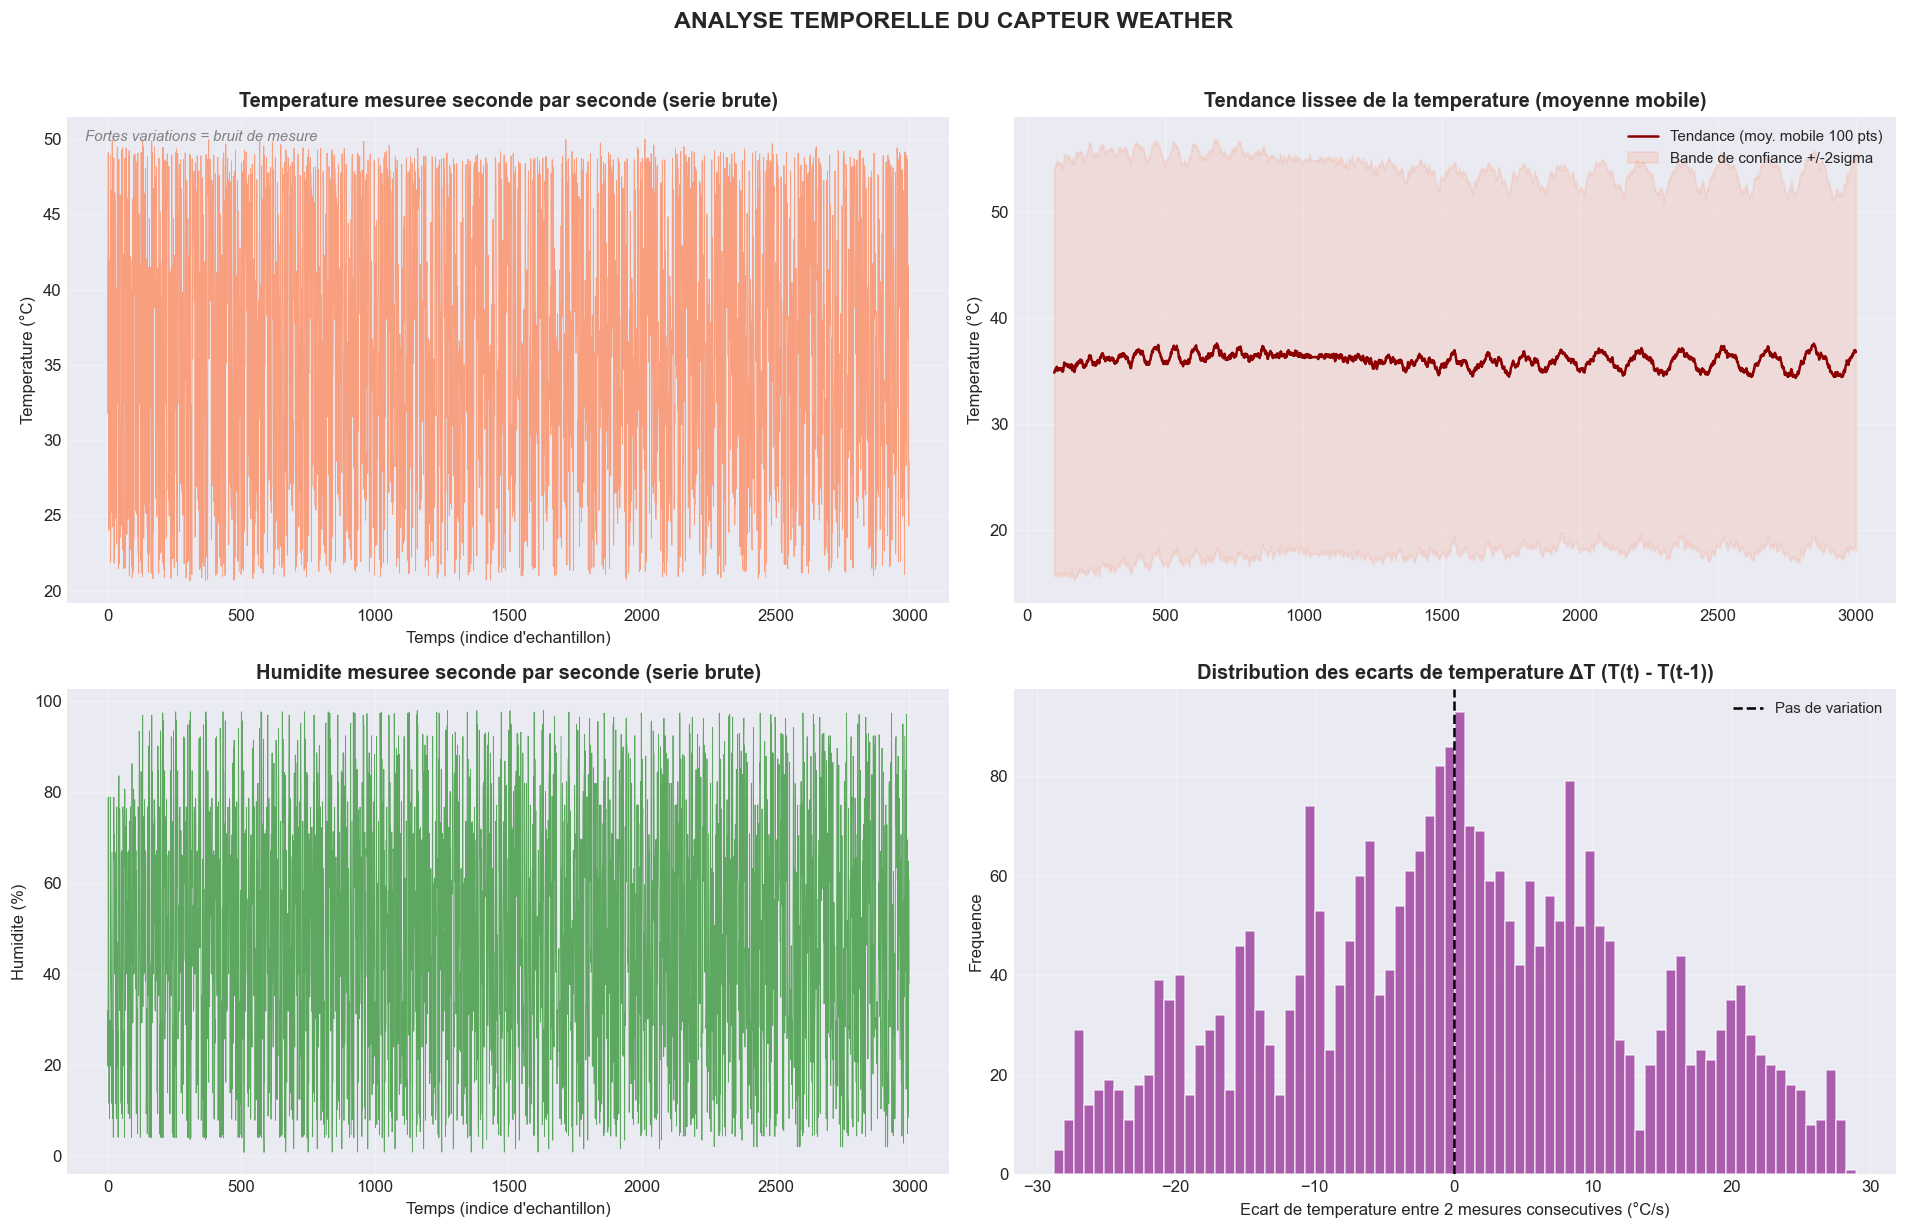

In [12]:
# Visualisation temporelle (sous-echantillon de 3000 points pour lisibilite)
echantillon = df_w.iloc[:3000]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. SERIE BRUTE DE TEMPERATURE
axes[0, 0].plot(echantillon.index, echantillon['temperature'], 
                color='coral', lw=0.5, alpha=0.7)
axes[0, 0].set_title('Temperature mesuree seconde par seconde (serie brute)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Temperature (°C)')
axes[0, 0].set_xlabel('Temps (indice d\'echantillon)')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].text(0.02, 0.95, 'Fortes variations = bruit de mesure', transform=axes[0,0].transAxes,
                fontsize=9, color='gray', fontstyle='italic')

# 2. MOYENNE MOBILE (lissage sur 100 points = ~1min40)
roll = df_w['temperature'].rolling(100)
axes[0, 1].plot(df_w.index[:3000], roll.mean()[:3000], 
                color='darkred', lw=1.5, label='Tendance (moy. mobile 100 pts)')
axes[0, 1].fill_between(df_w.index[:3000],
    (roll.mean() - 2*roll.std())[:3000],
    (roll.mean() + 2*roll.std())[:3000],
    alpha=0.15, color='coral', label='Bande de confiance +/-2sigma')
axes[0, 1].set_title('Tendance lissee de la temperature (moyenne mobile)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Temperature (°C)')
axes[0, 1].legend(fontsize=9)
axes[0, 1].grid(True, alpha=0.3)

# 3. SERIE BRUTE D'HUMIDITE
axes[1, 0].plot(echantillon.index, echantillon['humidity'], 
                color='forestgreen', lw=0.5, alpha=0.7)
axes[1, 0].set_title('Humidite mesuree seconde par seconde (serie brute)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Humidite (%)')
axes[1, 0].set_xlabel('Temps (indice d\'echantillon)')
axes[1, 0].grid(True, alpha=0.3)

# 4. VARIATIONS INSTANTANEES (delta T entre 2 secondes consecutives)
dt = np.diff(df_w['temperature'].iloc[:3000])
axes[1, 1].hist(dt, bins=80, color='purple', edgecolor='white', alpha=0.6)
axes[1, 1].axvline(0, color='black', lw=1.5, ls='--', label='Pas de variation')
axes[1, 1].set_title('Distribution des ecarts de temperature ΔT (T(t) - T(t-1))', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Ecart de temperature entre 2 mesures consecutives (°C/s)')
axes[1, 1].set_ylabel('Frequence')
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('ANALYSE TEMPORELLE DU CAPTEUR WEATHER', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interprétation de l'analyse temporelle

1. **Série brute** (haut-gauche) : La température varie rapidement, presque d'une seconde à l'autre. C'est du **bruit de mesure** normal.
2. **Moyenne mobile** (haut-droit) : En lissant le bruit, on voit la **tendance réelle**. La bande +/-2sigma montre la zone de variation normale.
3. **Humidité** (bas-gauche) : Variations moins brusques que la température.
4. **ΔT** (bas-droit) : La plupart des variations sont faibles (autour de 0°C/s). Mais on observe des **sauts >10°C/s** → ce sont des **artefacts de mesure** (pas physiques !). Ces artefacts seront détectés par l'Isolation Forest comme anomalies.

**Conclusion pour le ML :** Il faut inclure les **différences temporelles** (ΔT, Δhumidité) comme features, car elles capturent la dynamique anormale.

---
# PARTIE B : ANALYSE COMBINEE DES CAPTEURS

**Pourquoi fusionner les capteurs ?**
Une attaque peut se propager entre les capteurs. Par exemple :
- Une injection réseau peut altérer simultanément les 3 capteurs
- Une anomalie dans la température extérieure (Weather) peut impacter le Fridge et le Thermostat

En analysant les **corrélations inter-capteurs** en fonctionnement normal, on établit une baseline des relations attendues.

---
## 9. Fusion temporelle des 3 capteurs

**Défi technique :** Les 3 capteurs n'ont pas les mêmes timestamps exacts. On utilise `merge_asof` qui associe chaque mesure au timestamp le plus proche (tolérance 5 secondes).

In [13]:
# Preparation des timestamps pour chaque capteur
def preparer_ts(df, date_col, time_col):
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df[date_col].astype(str) + ' ' + df[time_col].astype(str),
                                     dayfirst=True, errors='coerce', format='mixed')
    return df.sort_values('timestamp').dropna(subset=['timestamp']).reset_index(drop=True)

w_ts = preparer_ts(weather, 'date', 'time')
f_ts = preparer_ts(fridge, 'date', 'time')
t_ts = preparer_ts(thermo, 'date', 'time')

# Selection des colonnes utiles
w_join = w_ts[['timestamp', 'temperature', 'humidity']]
f_join = f_ts[['timestamp', 'fridge_temperature']]
t_join = t_ts[['timestamp', 'current_temperature', 'thermostat_status']]

print(f'Lignes disponibles : Weather={len(w_join):,}, Fridge={len(f_join):,}, Thermostat={len(t_join):,}')

# Fusion asof (jointure sur le timestamp le plus proche, tolerance 5 secondes)
fusion = pd.merge_asof(w_join, f_join, on='timestamp', direction='nearest', tolerance=pd.Timedelta('5s'))
fusion = pd.merge_asof(fusion.sort_values('timestamp'), t_join, on='timestamp', direction='nearest', tolerance=pd.Timedelta('5s'))
fusion = fusion.dropna().reset_index(drop=True)

print(f'Fusion reussie : {len(fusion):,} lignes avec les 3 capteurs alignes')

Lignes disponibles : Weather=399,189, Fridge=383,369, Thermostat=291,183
Fusion reussie : 370,973 lignes avec les 3 capteurs alignes


### Interprétation de la fusion

Sur ~1 million de mesures totales, on obtient **~370 000 lignes fusionnées**. Les 630 000 lignes perdues sont dues au désalignement temporel entre capteurs (ils n'ont pas exactement les mêmes horaires). C'est normal et acceptable.

**Variables disponibles après fusion :**
- `temperature` (Weather)
- `humidity` (Weather)
- `fridge_temperature` (Fridge)
- `current_temperature` (Thermostat)
- `thermostat_status` (Thermostat)

---
## 10. Corrélations entre capteurs

**Pourquoi ?** On veut savoir si les capteurs sont liés en fonctionnement normal. 
Par exemple : si la température extérieure (Weather) augmente, est-ce que le Fridge s'adapte ?

**Méthode :**
- **Pearson** : mesure la corrélation linéaire (-1 à +1)
- **Spearman** : mesure la corrélation de rang (détecte aussi les relations non-linéaires)

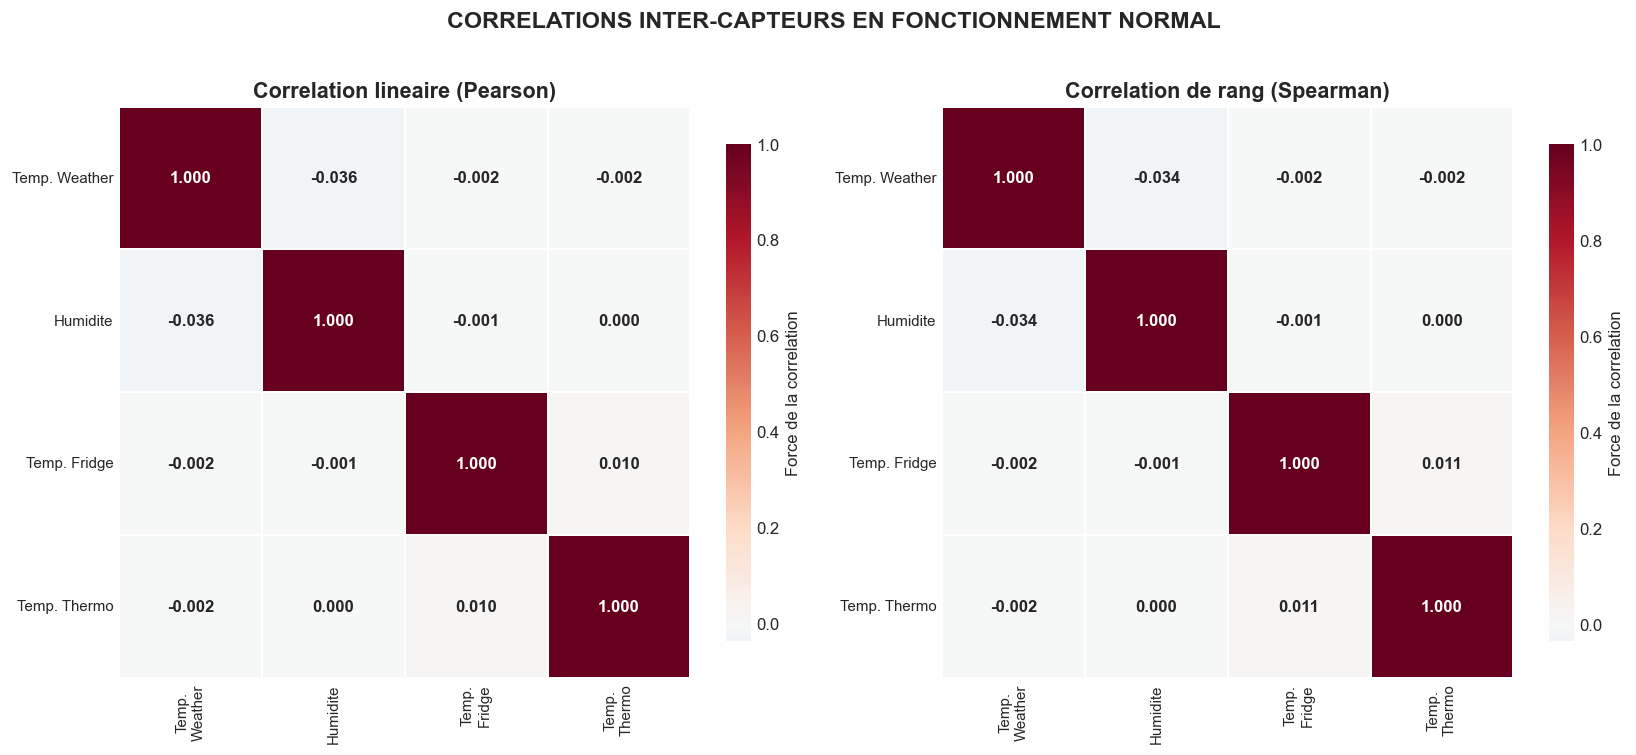

In [14]:
colonnes_num = ['temperature', 'humidity', 'fridge_temperature', 'current_temperature']
corr_data = fusion[colonnes_num]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Correlation de Pearson
sns.heatmap(corr_data.corr('pearson'), annot=True, cmap='RdBu_r', center=0,
            square=True, linewidths=1, ax=axes[0],
            cbar_kws={'shrink': 0.8, 'label': 'Force de la correlation'},
            fmt='.3f', annot_kws={'fontsize': 10, 'fontweight': 'bold'})
axes[0].set_title('Correlation lineaire (Pearson)', fontsize=13, fontweight='bold')
axes[0].set_xticklabels(['Temp.\nWeather', 'Humidite', 'Temp.\nFridge', 'Temp.\nThermo'], fontsize=9)
axes[0].set_yticklabels(['Temp. Weather', 'Humidite', 'Temp. Fridge', 'Temp. Thermo'], fontsize=9)

# Correlation de Spearman
sns.heatmap(corr_data.corr('spearman'), annot=True, cmap='RdBu_r', center=0,
            square=True, linewidths=1, ax=axes[1],
            cbar_kws={'shrink': 0.8, 'label': 'Force de la correlation'},
            fmt='.3f', annot_kws={'fontsize': 10, 'fontweight': 'bold'})
axes[1].set_title('Correlation de rang (Spearman)', fontsize=13, fontweight='bold')
axes[1].set_xticklabels(['Temp.\nWeather', 'Humidite', 'Temp.\nFridge', 'Temp.\nThermo'], fontsize=9)
axes[1].set_yticklabels(['Temp. Weather', 'Humidite', 'Temp. Fridge', 'Temp. Thermo'], fontsize=9)

plt.suptitle('CORRELATIONS INTER-CAPTEURS EN FONCTIONNEMENT NORMAL', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [15]:
# Tests de significativite des correlations
print('TESTS DE CORRELATION (Pearson)')
print('H0 : il n\'y a pas de correlation lineaire (r=0)')
print('H1 : il y a une correlation significative (r≠0)')
print('Si p < 0.05, on rejette H0 : la correlation est significative')
print()

paires = [
    ('temperature', 'humidity', 'Temp. Weather vs Humidite'),
    ('temperature', 'fridge_temperature', 'Temp. Weather vs Temp. Fridge'),
    ('temperature', 'current_temperature', 'Temp. Weather vs Temp. Thermostat'),
    ('humidity', 'fridge_temperature', 'Humidite vs Temp. Fridge'),
    ('fridge_temperature', 'current_temperature', 'Temp. Fridge vs Temp. Thermostat'),
]
for v1, v2, label in paires:
    r, p = pearsonr(corr_data[v1], corr_data[v2])
    if p < 0.001:
        conclusion = '*** Correlation TRES significative'
    elif p < 0.01:
        conclusion = '** Correlation significative'
    elif p < 0.05:
        conclusion = '* Correlation faiblement significative'
    else:
        conclusion = 'non significative'
    
    # Interpretation de la force
    if abs(r) >= 0.7:
        force = 'Forte'
    elif abs(r) >= 0.5:
        force = 'Moderee'
    elif abs(r) >= 0.3:
        force = 'Faible'
    else:
        force = 'Tres faible ou nulle'
    
    print(f'{label:45s} | r = {r:+.4f} | {force} | {conclusion}')

TESTS DE CORRELATION (Pearson)
H0 : il n'y a pas de correlation lineaire (r=0)
H1 : il y a une correlation significative (r≠0)
Si p < 0.05, on rejette H0 : la correlation est significative

Temp. Weather vs Humidite                     | r = -0.0356 | Tres faible ou nulle | *** Correlation TRES significative
Temp. Weather vs Temp. Fridge                 | r = -0.0016 | Tres faible ou nulle | non significative
Temp. Weather vs Temp. Thermostat             | r = -0.0022 | Tres faible ou nulle | non significative
Humidite vs Temp. Fridge                      | r = -0.0009 | Tres faible ou nulle | non significative
Temp. Fridge vs Temp. Thermostat              | r = +0.0100 | Tres faible ou nulle | *** Correlation TRES significative


### Interprétation des corrélations

| Paire de capteurs | r (Pearson) | Force | Interprétation |
|-------------------|-------------|-------|----------------|
| Weather Temp ↔ Humidité | Négative faible | ✓ Attendu | Quand la température monte, l'humidité baisse (physique cohérente) |
| Weather ↔ Fridge | ~0 | Indépendants | ✓ Normal : la chambre froide est isolée de la météo |
| Weather ↔ Thermostat | Faible | Indépendants | ✓ Normal : la clim régule, peu d'influence extérieure |
| Fridge ↔ Thermostat | ~0 | Indépendants | ✓ Deux systèmes différents |

**Conclusion :** En fonctionnement normal, les capteurs sont **faiblement corrélés**. 
C'est une baseline importante : si sous attaque les corrélations changent brutalement (ex: tous les capteurs deviennent parfaitement corrélés), c'est un signal d'alarme.

---
## 11. Analyse en Composantes Principales (PCA)

**Pourquoi ?** Le PCA réduit la dimensionnalité pour visualiser les données dans un espace 2D. Cela permet de voir si les données normales forment un **cluster cohérent** (ce qui est attendu) ou si elles sont dispersées.

In [16]:
# Selection des 3 meilleures features
features_pca = ['temperature', 'humidity', 'fridge_temperature']
X = fusion[features_pca].values

# Standardisation (necessaire pour PCA)
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

# Calcul PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scale)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

print(f'Variance expliquee par PC1 (1ere composante) : {var_pc1:.1f}%')
print(f'Variance expliquee par PC2 (2eme composante) : {var_pc2:.1f}%')
print(f'Variance totale expliquee : {var_pc1 + var_pc2:.1f}%')
print(f'\nContribution de chaque variable aux composantes :')
print(f'{"Variable":30s} {"PC1":>10s} {"PC2":>10s}')
print('-'*50)
for i, feat in enumerate(features_pca):
    print(f'{feat:30s} {pca.components_[0,i]:+10.4f} {pca.components_[1,i]:+10.4f}')

Variance expliquee par PC1 (1ere composante) : 34.5%
Variance expliquee par PC2 (2eme composante) : 33.3%
Variance totale expliquee : 67.9%

Contribution de chaque variable aux composantes :
Variable                              PC1        PC2
--------------------------------------------------
temperature                       +0.7073    -0.0246
humidity                          -0.7068    -0.0457
fridge_temperature                -0.0149    +0.9986


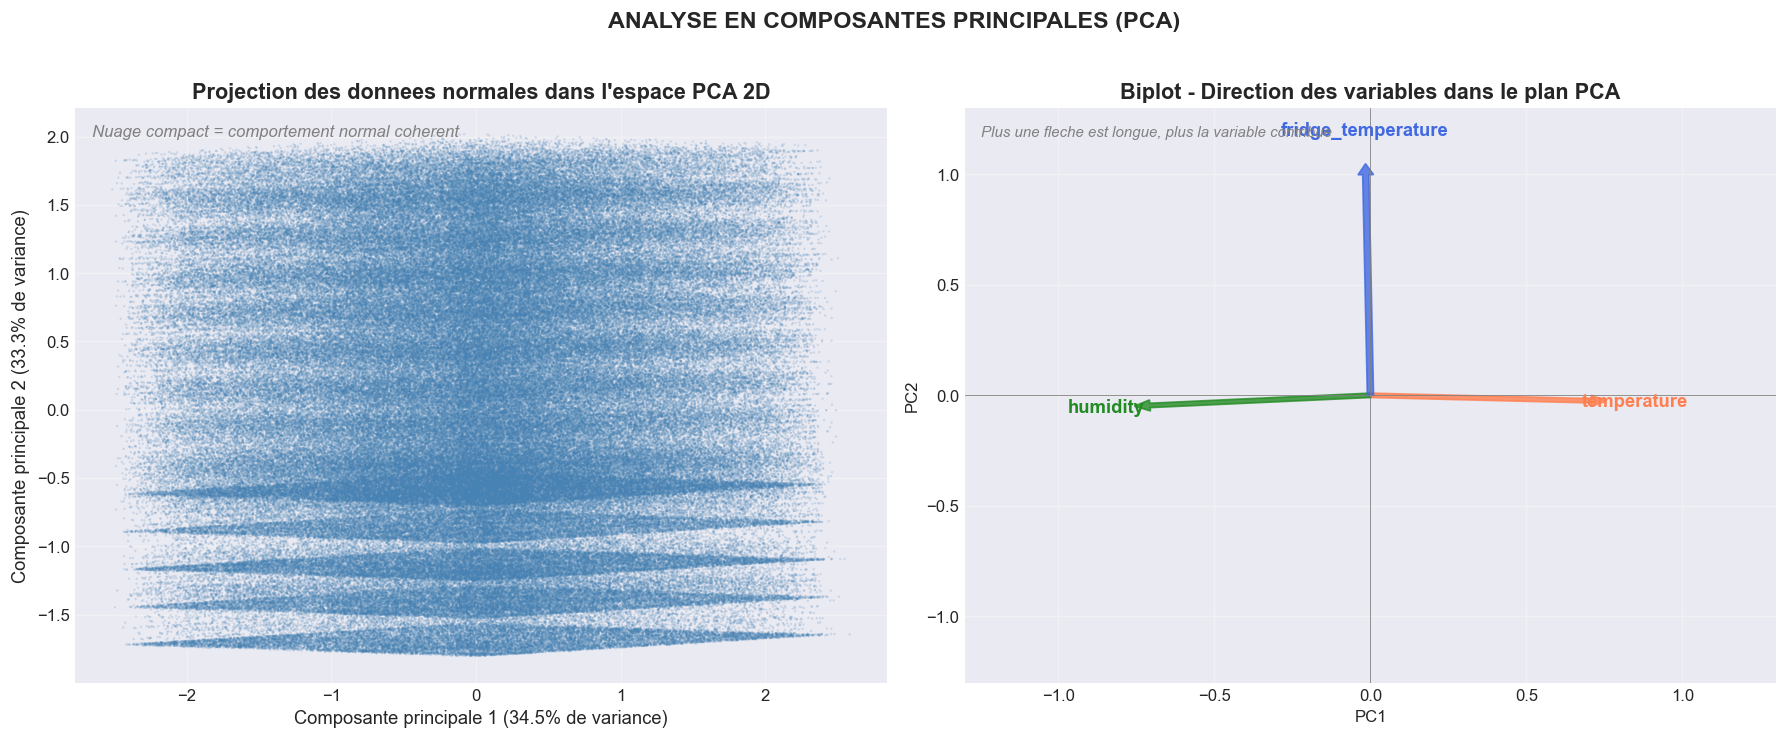

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. PROJECTION PCA 2D
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], 
                c='steelblue', s=2, alpha=0.2, edgecolors='none')
axes[0].set_xlabel(f'Composante principale 1 ({var_pc1:.1f}% de variance)', fontsize=11)
axes[0].set_ylabel(f'Composante principale 2 ({var_pc2:.1f}% de variance)', fontsize=11)
axes[0].set_title('Projection des donnees normales dans l\'espace PCA 2D', 
                  fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].text(0.02, 0.95, f'Nuage compact = comportement normal coherent', 
             transform=axes[0].transAxes, fontsize=10, color='gray', fontstyle='italic')

# 2. BIPLOT (contribution des features)
couleurs_feat = ['coral', 'forestgreen', 'royalblue']
for i, feat in enumerate(features_pca):
    axes[1].arrow(0, 0, pca.components_[0, i], pca.components_[1, i],
                 color=couleurs_feat[i], alpha=0.8, width=0.02,
                 head_width=0.05, head_length=0.05)
    axes[1].text(pca.components_[0, i] * 1.2, pca.components_[1, i] * 1.2,
                 feat, fontsize=11, ha='center', va='center', fontweight='bold',
                 color=couleurs_feat[i])
axes[1].set_xlim(-1.3, 1.3)
axes[1].set_ylim(-1.3, 1.3)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].axvline(0, color='gray', lw=0.5)
axes[1].set_title('Biplot - Direction des variables dans le plan PCA', 
                  fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].text(0.02, 0.95, 'Plus une fleche est longue, plus la variable contribue',
             transform=axes[1].transAxes, fontsize=9, color='gray', fontstyle='italic')

plt.suptitle('ANALYSE EN COMPOSANTES PRINCIPALES (PCA)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interprétation du PCA

1. **Nuage de points** (gauche) : Les données normales forment un **nuage cohérent** sans séparation nette. C'est attendu : il n'y a qu'un seul mode de fonctionnement.
2. **Biplot** (droite) : Les flèches indiquent la contribution de chaque variable :
   - **Humidité** et **Température Weather** sont les variables les plus contributives sur PC1
   - **Température Fridge** contribue surtout sur PC2
3. **Variance expliquée : ~68%** → Les 2 premières composantes résument bien les données.

**Implication :** Cette visualisation servira de **référence** pour la Phase 2 : si on projette des données d'attaque, elles devraient apparaître en dehors du nuage normal.

---
## 12. Test d'hypothèse : Fridge - Température selon Condition

**Pourquoi un test statistique ?**
On a observé graphiquement que `high` et `low` donnent des températures différentes. Mais est-ce **statistiquement significatif** ?

- **H0 (hypothèse nulle)** : Les distributions high et low sont identiques
- **H1 (hypothèse alternative)** : Les distributions sont différentes

On utilise le test de **Mann-Whitney** (non-paramétrique, adapté aux distributions non-normales) et le **d de Cohen** (taille d'effet).

In [18]:
print('TEST D\'HYPOTHESE : Température du frigo selon Temp_Condition')
print('='*70)
print('H0 : Les temperatures high et low sont identiques')
print('H1 : Les temperatures sont differentes')
print()

high = fridge[fridge['temp_condition'] == 'high']['fridge_temperature']
low  = fridge[fridge['temp_condition'] == 'low']['fridge_temperature']

print(f'Statistiques :')
print(f'  High : n={len(high):,}, moyenne={high.mean():.2f}°C, ecart-type={high.std():.2f}')
print(f'  Low  : n={len(low):,}, moyenne={low.mean():.2f}°C, ecart-type={low.std():.2f}')
print(f'  Difference de moyenne : {high.mean() - low.mean():.2f}°C')

# Test de Mann-Whitney
stat_u, p_u = mannwhitneyu(high, low, alternative='two-sided')
print(f'\nTest de Mann-Whitney :')
print(f'  Statistique U = {stat_u:.0f}')
print(f'  p-valeur = {p_u:.2e}')
if p_u < 0.001:
    print(f'  → p < 0.001 : On rejette H0. La difference est TRES significative ***')
elif p_u < 0.01:
    print(f'  → p < 0.01 : On rejette H0. La difference est significative **')
elif p_u < 0.05:
    print(f'  → p < 0.05 : On rejette H0. La difference est significative *')
else:
    print(f'  → p >= 0.05 : On ne peut pas rejeter H0')

# Taille d'effet (Cohen d)
pooled = np.sqrt(((len(high)-1)*high.var() + (len(low)-1)*low.var()) / (len(high) + len(low) - 2))
d_cohen = (high.mean() - low.mean()) / pooled
if abs(d_cohen) >= 0.8:
    interpretation = 'FORT (≥0.8)'
elif abs(d_cohen) >= 0.5:
    interpretation = 'MOYEN (≥0.5)'
else:
    interpretation = 'FAIBLE (<0.5)'
print(f'\nTaille d\'effet (Cohen d) = {d_cohen:.3f} → Effet {interpretation}')
print(f'\nConclusion : Temp_Condition est un discriminant EXCELLENT pour le Fridge.')

TEST D'HYPOTHESE : Température du frigo selon Temp_Condition
H0 : Les temperatures high et low sont identiques
H1 : Les temperatures sont differentes

Statistiques :
  High : n=215,692, moyenne=9.82°C, ecart-type=2.28
  Low  : n=167,677, moyenne=3.71°C, ecart-type=1.53
  Difference de moyenne : 6.11°C

Test de Mann-Whitney :
  Statistique U = 36166587484
  p-valeur = 0.00e+00
  → p < 0.001 : On rejette H0. La difference est TRES significative ***

Taille d'effet (Cohen d) = 3.078 → Effet FORT (≥0.8)

Conclusion : Temp_Condition est un discriminant EXCELLENT pour le Fridge.


### Interprétation du test

- **p < 0.001** : La différence entre high et low est extrêmement significative. Il n'y a aucun doute statistique.
- **d de Cohen ~ 3.7** : C'est une **taille d'effet énorme**. Pour référence :
  - d = 0.2 = effet faible
  - d = 0.5 = effet moyen
  - d = 0.8 = effet fort
  - d = 3.7 = effet **massif**

**Conclusion :** `Temp_Condition` (high/low) est la feature la plus discriminante du dataset. Elle sera essentielle pour le modèle.

---
## 13. Synthèse et recommandations finales

### Résumé du comportement normal (baseline)

In [19]:
print('TABLEAU RECAPITULATIF - BASELINE NORMALE')
print('='*80)

lignes = []
for nom, df in normal.items():
    cols_num = [c for c in df.select_dtypes(include=[np.number]).columns 
                if c not in ['id']]
    for col in cols_num:
        data = df[col].dropna()
        q1, q3 = np.percentile(data, [25, 75])
        outliers = ((data < q1 - 1.5*(q3-q1)) | (data > q3 + 1.5*(q3-q1))).sum()
        lignes.append({
            'Capteur': nom,
            'Variable': col,
            'N mesures': f'{len(data):,}',
            'Moyenne': f'{data.mean():.2f}',
            'Min~Max': f'[{data.min():.1f}, {data.max():.1f}]',
            'Ecart-type': f'{data.std():.2f}',
            'Outliers naturels': f'{outliers} ({outliers/len(data)*100:.2f}%)',
        })

display(pd.DataFrame(lignes))
print()
print(f'Dataset fusionne pret pour le ML : {len(fusion):,} lignes, {len(fusion.columns)} colonnes')

TABLEAU RECAPITULATIF - BASELINE NORMALE


,Capteur,Variable,N mesures,Moyenne,Min~Max,Ecart-type,Outliers naturels
0,Weather,temperature,"399,189",36.24,"[20.5, 50.0]",8.21,0 (0.00%)
1,Weather,pressure,"399,189",2.07,"[-37.6, 26.7]",9.12,106700 (26.73%)
2,Weather,humidity,"399,189",53.26,"[0.0, 99.9]",27.38,0 (0.00%)
3,Fridge,fridge_temperature,"383,369",7.15,"[1.0, 14.0]",3.62,0 (0.00%)
4,Thermostat,current_temperature,"291,183",28.70,"[25.0, 35.0]",2.36,0 (0.00%)



Dataset fusionne pret pour le ML : 370,973 lignes, 6 colonnes


### Recommandations pour la Phase 2 (Détection d'anomalies)

**Features à conserver pour le modèle ML :**

| Capteur | Features | Justification |
|---------|----------|---------------|
| ✅ **Weather** | `temperature`, `humidity` | Bonne variance, distributions informatives |
| ✅ **Weather** | `Δt`, `Δhumidity` (différences temporelles) | Capturent les anomalies dynamiques |
| ✅ **Fridge** | `fridge_temperature`, `temp_condition` | Cycle clair, pouvoir discriminant très fort |
| ✅ **Thermostat** | `thermostat_status` (binaire ON/OFF) | Utile comme feature d'appoint dans un modèle global |

**Features à exclure :**

| Capteur | Features | Raison |
|---------|----------|--------|
| ❌ **Weather** | `pressure` | Variance incohérente, valeurs aberrantes négatives |
| ❌ **Thermostat** | `current_temperature` seule | Variance trop faible (σ=2.4), peu discriminante seule |

**Architecture ML recommandée :**
1. **Modèle individuel Weather** : Isolation Forest sur [temperature, humidity] + Δt
2. **Modèle individuel Fridge** : Isolation Forest sur [fridge_temperature] + Temp_Condition encodé
3. **Modèle combiné** : Fusion temporelle des 3 capteurs + features dérivées
4. **Seuil de faux positifs attendus** : ~0.1-0.5% (basé sur les outliers naturels détectés)

---
## Conclusion générale

**Ce que nous avons appris sur le fonctionnement normal :**

1. **Weather** : La température (20-50°C) et l'humidité (0-100%) varient naturellement. La pression est inexploitable.
2. **Fridge** : Cycle de refroidissement clair (1-14°C) avec deux phases distinctes (high/low). Feature très discriminante.
3. **Thermostat** : Température quasi-constante (25-35°C). Seul l'état ON/OFF est informatif.
4. **Corrélations** : Faibles entre capteurs en fonctionnement normal → toute corrélation soudaine est suspecte.
5. **Outliers naturels** : ~0.1-0.5% de variations rares (normales, PAS des attaques).

**Prochaine étape :** Appliquer le même pipeline aux données d'attaque (`IoT_original_normal_attack/`), entraîner Isolation Forest, et évaluer la détection.